In [1]:
import numpy as np
import pandas as pd

from sklearn.datasets import load_breast_cancer

# Load dataset
data = load_breast_cancer()

# Create DataFrame
df = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

# Add target column
df["Diagnosis"] = data.target

print("Dataset Loaded Successfully!")
print("\nFirst 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

Dataset Loaded Successfully!

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  w

In [2]:
# Separate input features and target

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Features (X) Shape:", X.shape)
print("Target (y) Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features (X) Shape: (569, 30)
Target (y) Shape: (569,)

Target Distribution:
Diagnosis
1    357
0    212
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (455, 30)
Testing Features: (114, 30)

Training Target Distribution:
Diagnosis
1    285
0    170
Name: count, dtype: int64

Testing Target Distribution:
Diagnosis
1    72
0    42
Name: count, dtype: int64


In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit on training data and transform
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")

print("\nTraining Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nFirst 5 Scaled Values:")
print(X_train_scaled[:5, :5])

Feature Scaling Completed!

Training Data Shape: (455, 30)
Testing Data Shape: (114, 30)

First 5 Scaled Values:
[[-1.07200079 -0.6584246  -1.0880801  -0.93927364 -0.13593988]
 [ 1.74874285  0.06650173  1.75115682  1.74555856  1.27446827]
 [-0.97473376 -0.93112416 -0.99770871 -0.86758911 -0.61351479]
 [-0.14510328 -1.2151862  -0.12301315 -0.25319178  0.66448162]
 [-0.77161734 -0.08121053 -0.8037004  -0.73292668 -0.6722818 ]]


In [5]:
from sklearn.linear_model import LogisticRegression

# Create model
model = LogisticRegression(random_state=42)

# Train model
model.fit(X_train_scaled, y_train)

print("Model Training Completed Successfully!")

print("\nModel:", model)

Model Training Completed Successfully!

Model: LogisticRegression(random_state=42)


In [6]:
# Predict using testing data
y_pred = model.predict(X_test_scaled)

print("Predictions Generated Successfully!")

print("\nFirst 10 Predictions:")
print(y_pred[:10])

print("\nFirst 10 Actual Values:")
print(y_test.values[:10])

Predictions Generated Successfully!

First 10 Predictions:
[0 1 0 1 0 1 1 0 0 0]

First 10 Actual Values:
[0 1 0 1 0 1 1 0 0 0]


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Model Evaluation Results\n")

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("Precision:", round(precision_score(y_test, y_pred) * 100, 2), "%")

print("Recall:", round(recall_score(y_test, y_pred) * 100, 2), "%")

print("F1 Score:", round(f1_score(y_test, y_pred) * 100, 2), "%")

Model Evaluation Results

Accuracy: 98.25 %
Precision: 98.61 %
Recall: 98.61 %
F1 Score: 98.61 %


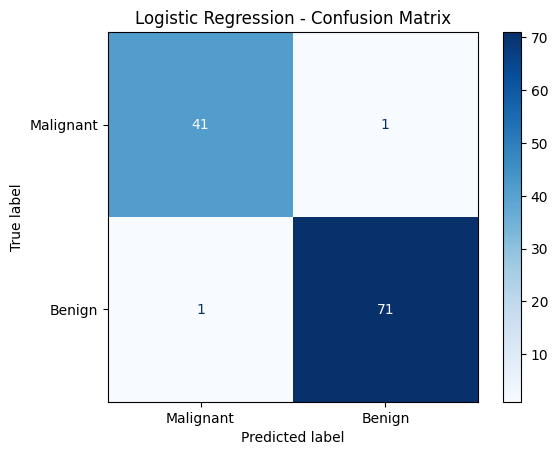

In [9]:
import matplotlib.pyplot as plt

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Malignant", "Benign"]
)

display.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [10]:
from sklearn.metrics import classification_report

print("Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Malignant", "Benign"]
    )
)

Classification Report:

              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

